# Stage 12 — Candidate analogue generation and prioritization

This notebook creates **ligand-based design hypotheses** from supported Stage 11 training-set MMP transformations and low-activity training compounds (including primary activity-cliff members). It applies the already selected **fixed Stage 05 list of 250 features** and the saved Stage 08 ExtraTrees, CatBoost, and SVR models. It does not refit models, redo feature selection, or read locked-test activities/predictions.

Candidate predictions are hypotheses for experimental follow-up, not measured pIC50 values or mechanistic claims. The notebook generates a bounded set of candidates, checks exact feature availability without imputation, calculates three training-defined AD flags, and recommends up to three diverse candidates only when they meet the declared criteria. Run cells in order and review each displayed audit before continuing.


In [3]:
# 1. Imports, project paths, fixed settings, outputs, and local descriptor helpers.

import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

from rdkit import Chem, DataStructs
from rdkit.Chem import (
    AllChem,
    Descriptors,
    rdFingerprintGenerator,
    rdMolDescriptors,
    QED,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
import joblib

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError(
        "Open this notebook from the BRD4 QSAR project folder."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    OUTPUTS,
    load_config,
    stage_dir,
    write_manifest,
    save_figure,
    setup_plotting,
)

# Keep descriptor definitions consistent with Stage 03.
BASIC = {
    "MolWt": Descriptors.MolWt,
    "MolLogP": Descriptors.MolLogP,
    "TPSA": rdMolDescriptors.CalcTPSA,
    "HBD": rdMolDescriptors.CalcNumHBD,
    "HBA": rdMolDescriptors.CalcNumHBA,
    "RotatableBonds": rdMolDescriptors.CalcNumRotatableBonds,
    "RingCount": Descriptors.RingCount,
    "HeavyAtomCount": Descriptors.HeavyAtomCount,
    "FractionCSP3": rdMolDescriptors.CalcFractionCSP3,
}


def lowest_energy_conformer(
    mol,
    num_conformers=50,
    seed=42,
    prune_rms=0.5,
    max_iterations=200,
):
    """Return the lowest-energy ETKDG/MMFF94s conformer and search metadata.

    Molecules without complete MMFF parameters are skipped. UFF is not used.
    """
    mol_h = Chem.AddHs(Chem.Mol(mol))

    if not AllChem.MMFFHasAllMoleculeParams(mol_h):
        return None, {
            "status": "no_mmff_parameters",
            "conformers_generated": 0,
        }

    params = AllChem.ETKDGv3()
    params.randomSeed = int(seed)
    params.numThreads = 1
    params.pruneRmsThresh = float(prune_rms)

    conformer_ids = list(
        AllChem.EmbedMultipleConfs(
            mol_h,
            numConfs=int(num_conformers),
            params=params,
        )
    )

    if not conformer_ids:
        return None, {
            "status": "embedding_failed",
            "conformers_generated": 0,
        }

    outcomes = AllChem.MMFFOptimizeMoleculeConfs(
        mol_h,
        numThreads=1,
        maxIters=int(max_iterations),
        mmffVariant="MMFF94s",
    )

    valid = [
        (int(conf_id), int(status), float(energy))
        for conf_id, (status, energy) in zip(conformer_ids, outcomes)
        if np.isfinite(energy)
    ]

    if not valid:
        return None, {
            "status": "optimization_failed",
            "conformers_generated": len(conformer_ids),
            "force_field": "MMFF94s",
        }

    converged = [item for item in valid if item[1] == 0]
    pool = converged if converged else valid
    best_id, best_status, best_energy = min(pool, key=lambda item: item[2])

    best_conformer = Chem.Conformer(mol_h.GetConformer(best_id))
    mol_h.RemoveAllConformers()
    mol_h.AddConformer(best_conformer, assignId=True)

    return mol_h, {
        "status": "converged" if best_status == 0 else "best_energy_not_converged",
        "conformers_generated": len(conformer_ids),
        "converged_conformers": len(converged),
        "selected_energy": best_energy,
        "force_field": "MMFF94s",
    }


setup_plotting()
CFG = load_config()
SEED = int(CFG.get("seed", 42))
FP_RADIUS = int(CFG.get("fingerprint_radius", 2))
FP_SIZE = int(CFG.get("fingerprint_bits", 2048))
USE_CHIRALITY = bool(CFG.get("use_chirality", True))

STAGE_DIR = stage_dir("12_candidate_generation_prioritization")
TABLE_DIR = STAGE_DIR / "tables"
FIGURE_DIR = STAGE_DIR / "figures"

print(f"Project: {PROJECT_ROOT}")
print(f"Stage 12 output: {STAGE_DIR}")
print(
    f"Morgan settings: radius={FP_RADIUS}, bits={FP_SIZE}, "
    f"chirality={USE_CHIRALITY}"
)
print("Conformer search: ETKDGv3 with MMFF94s; no UFF fallback.")

Project: c:\Users\USER\Documents\E\Code
Stage 12 output: C:\Users\USER\Documents\E\Code\outputs\12_candidate_generation_prioritization
Morgan settings: radius=2, bits=2048, chirality=True
Conformer search: ETKDGv3 with MMFF94s; no UFF fallback.


In [4]:
# 2. Load only training activities/structures and Stage 11 SAR tables; verify fixed 250 inputs.
CLEANED = OUTPUTS / "02_clean_data/tables/cleaned_activity.csv"
TRAIN_IDS = OUTPUTS / "04_train_test_split/tables/train_ids.csv"
TRAIN_X = OUTPUTS / "05_feature_selection/tables/train_selected_features.parquet"
TRAIN_Y = OUTPUTS / "05_feature_selection/tables/train_target.parquet"
SELECTED = OUTPUTS / "05_feature_selection/tables/selected_features.csv"
MMP_TRANS = OUTPUTS / "11_mmp_activity_cliffs/tables/mmp_enriching_transformations.csv"
MMP_FRAGS = OUTPUTS / "11_mmp_activity_cliffs/tables/mmp_fragments_training.csv"
MMP_PAIRS = OUTPUTS / "11_mmp_activity_cliffs/tables/mmp_pairs_training.csv"
CLIFFS = OUTPUTS / "11_mmp_activity_cliffs/tables/primary_activity_cliffs_training.csv"
required = [CLEANED, TRAIN_IDS, TRAIN_X, TRAIN_Y, SELECTED, MMP_TRANS, MMP_FRAGS, MMP_PAIRS, CLIFFS]
missing = [p for p in required if not p.is_file()]
if missing: raise FileNotFoundError("Run Stages 02–05 and 11 first. Missing:\n" + "\n".join(map(str,missing)))
selected = pd.read_csv(SELECTED)["feature"].astype(str).tolist()
if len(selected) != 250 or len(set(selected)) != 250: raise ValueError(f"Expected 250 unique Stage 05 features; found {len(selected)}")
X_train = pd.read_parquet(TRAIN_X); y_train = pd.read_parquet(TRAIN_Y)["pIC50"]
X_train.index=X_train.index.astype(str); y_train.index=y_train.index.astype(str)
ids = pd.read_csv(TRAIN_IDS,dtype={"chembl_id":str}); ids["chembl_id"]=ids.chembl_id.astype(str)
X_train=X_train.reindex(ids.chembl_id).loc[:,selected].apply(pd.to_numeric,errors="coerce")
y_train=y_train.reindex(ids.chembl_id)
if X_train.isna().any().any() or not np.isfinite(X_train.to_numpy(float)).all(): raise ValueError("Training fixed-250 matrix has missing/infinite values; this pipeline does not impute.")
if y_train.isna().any() or not np.isfinite(y_train.to_numpy(float)).all(): raise ValueError("Training pIC50 contains missing/infinite values.")
# Read structures only, then attach training-only pIC50 from Stage 05 target.
smiles_all=pd.read_csv(CLEANED,usecols=["chembl_id","canonical_smiles"],dtype={"chembl_id":str})
train=ids[["chembl_id"]].merge(smiles_all,on="chembl_id",how="left",validate="one_to_one")
train["pIC50"]=train.chembl_id.map(y_train)
if train[["canonical_smiles","pIC50"]].isna().any().any(): raise ValueError("Missing training SMILES/activity after ID join.")
train["mol"]=[Chem.MolFromSmiles(s) for s in train.canonical_smiles]
if any(m is None for m in train.mol): raise ValueError("Invalid training SMILES found.")
train_ids_set=set(train.chembl_id)
trans=pd.read_csv(MMP_TRANS); frags=pd.read_csv(MMP_FRAGS,dtype={"chembl_id":str}); mmp_pairs=pd.read_csv(MMP_PAIRS); cliffs=pd.read_csv(CLIFFS,dtype={"chembl_id_a":str,"chembl_id_b":str})
qstats=mmp_pairs.groupby(["fragment_from","fragment_to"]).delta_pIC50_to_minus_from.agg(q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75)).reset_index()
trans=trans.merge(qstats,on=["fragment_from","fragment_to"],how="left",validate="one_to_one")
if not {"fragment_from","fragment_to","n_pairs","median_delta_pIC50","direction_consistency"}.issubset(trans.columns): raise ValueError("Stage 11 enriching transformation table has unexpected columns.")
if not {"chembl_id","core","substituent"}.issubset(frags.columns): raise ValueError("Stage 11 fragment table has unexpected columns.")
if not set(frags.chembl_id.astype(str)).issubset(train_ids_set): raise ValueError("Nontraining molecule found in Stage 11 fragment table.")
# Load Stage 08 fitted bundles; these are only called for prediction.
MODEL_NAMES=("ExtraTreesRegressor","CatBoostRegressor","SVR")
model_bundles={}
for name in MODEL_NAMES:
    path=OUTPUTS / f"08_final_model_evaluation/models/final_{name}.joblib"
    if not path.is_file(): raise FileNotFoundError(f"Missing saved Stage 08 model: {path}")
    bundle=joblib.load(path)
    model_bundles[name]=bundle if isinstance(bundle,dict) else {"model":bundle}
    model_features=model_bundles[name].get("feature_names",selected)
    if list(map(str,model_features)) != selected: raise ValueError(f"{name} saved model feature order differs from fixed Stage 05 250 list.")
train_lookup=train.set_index("chembl_id")
print(f"Training molecules: {len(train):,} | fixed features: {len(selected)}")
print(f"Supported enriching rules: {len(trans):,} | Stage 11 parent-fragment contexts: {len(frags):,} | primary cliffs: {len(cliffs):,}")
display(trans.sort_values(["median_delta_pIC50","n_pairs"],ascending=False).head(8))


Training molecules: 5,134 | fixed features: 250
Supported enriching rules: 1,236 | Stage 11 parent-fragment contexts: 41,657 | primary cliffs: 6


,fragment_from,fragment_to,n_pairs,n_distinct_cores,mean_delta_pIC50,sd_delta_pIC50,median_delta_pIC50,fraction_positive,fraction_negative,direction_consistency,status,q25,q75
0,CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,3,3,2.286404,0.512731,2.471047,1.000000,0.000000,1.000000,enriching,2.088986,2.576144
22,C=CCC[*:1],C[*:1],3,3,1.007607,1.425057,1.680801,0.666667,0.333333,0.666667,enriching,0.525733,1.826078
65,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,3,3,0.835770,1.555779,1.498311,0.666667,0.333333,0.666667,enriching,0.278351,1.724459
24,CO[*:1],O=S(=O)(NC1CC1)[*:1],3,3,0.980224,0.854861,1.369545,0.666667,0.000000,0.666667,enriching,0.684772,1.470335
329,CC(C)[*:1],CC(C)[C@H](O)[*:1],3,3,0.480602,1.492716,1.342423,0.666667,0.333333,0.666667,enriching,0.049692,1.342423
330,CC(C)C(=O)NCC[*:1],CC(C)[C@H](O)C(=O)NCC[*:1],3,3,0.480602,1.492716,1.342423,0.666667,0.333333,0.666667,enriching,0.049692,1.342423
331,CC(C)C(=O)NC[*:1],CC(C)[C@H](O)C(=O)NC[*:1],3,3,0.480602,1.492716,1.342423,0.666667,0.333333,0.666667,enriching,0.049692,1.342423
332,CC(C)C(=O)N[*:1],CC(C)[C@H](O)C(=O)N[*:1],3,3,0.480602,1.492716,1.342423,0.666667,0.333333,0.666667,enriching,0.049692,1.342423


In [5]:
# 3. Generate novel analogues by applying supported enriching MMP rules within observed training cores.
# A rule is applied only where its source substituent occurs in that exact training core context.
MIN_RULE_PAIRS=3; MIN_DIRECTION_CONSISTENCY=0.60
MAX_RULES=25; MAX_PARENTS_PER_RULE=8
train_canonical=set(Chem.MolToSmiles(m,canonical=True,isomericSmiles=True) for m in train.mol)
activity_map=train.set_index("chembl_id").pIC50.to_dict()
cliff_members=set(cliffs.get("chembl_id_a",pd.Series(dtype=str)).astype(str)) | set(cliffs.get("chembl_id_b",pd.Series(dtype=str)).astype(str))
# Keep Stage 11's supported enrichers and rank on median gain, support, then consistency.
ranked_rules=trans[(trans.n_pairs>=MIN_RULE_PAIRS)&(trans.direction_consistency>=MIN_DIRECTION_CONSISTENCY)&(trans.median_delta_pIC50>0)].copy()
ranked_rules=ranked_rules.sort_values(["median_delta_pIC50","n_pairs","direction_consistency"],ascending=False).head(MAX_RULES).reset_index(drop=True)

def zip_fragments(core_smiles, substituent_smiles):
    core=Chem.MolFromSmiles(str(core_smiles)); side=Chem.MolFromSmiles(str(substituent_smiles))
    if core is None or side is None: return None
    try:
        mol=Chem.molzip(core,side)
        if mol is None: return None
        Chem.SanitizeMol(mol)
        if any(a.GetAtomicNum()==0 for a in mol.GetAtoms()): return None
        return mol
    except Exception: return None

candidate_rows=[]; failures=[]
for rule_i,rule in ranked_rules.iterrows():
    contexts=frags[frags.substituent.astype(str).eq(str(rule.fragment_from))].copy()
    contexts["parent_pIC50"]=contexts.chembl_id.astype(str).map(activity_map)
    # Prioritize weak measured parents and explicit cliff members; only training labels are used.
    contexts["is_primary_cliff_member"]=contexts.chembl_id.astype(str).isin(cliff_members)
    contexts=contexts.dropna(subset=["parent_pIC50"]).sort_values(["is_primary_cliff_member","parent_pIC50"],ascending=[False,True],kind="stable").drop_duplicates(["chembl_id","core"]).head(MAX_PARENTS_PER_RULE)
    for parent in contexts.itertuples(index=False):
        mol=zip_fragments(parent.core,rule.fragment_to)
        if mol is None:
            failures.append({"rule_index":rule_i,"parent_id":str(parent.chembl_id),"core":parent.core,"from":rule.fragment_from,"to":rule.fragment_to,"reason":"molzip_or_sanitize_failed"}); continue
        smiles=Chem.MolToSmiles(mol,canonical=True,isomericSmiles=True)
        if smiles in train_canonical:
            failures.append({"rule_index":rule_i,"parent_id":str(parent.chembl_id),"core":parent.core,"from":rule.fragment_from,"to":rule.fragment_to,"reason":"already_present_in_training"}); continue
        candidate_rows.append({"candidate_id":f"C{len(candidate_rows)+1:04d}","parent_chembl_id":str(parent.chembl_id),"parent_smiles":str(train_lookup.loc[str(parent.chembl_id),"canonical_smiles"]),"parent_pIC50_training":float(parent.parent_pIC50),"parent_is_primary_cliff_member":bool(parent.is_primary_cliff_member),"core":str(parent.core),"fragment_from":str(rule.fragment_from),"fragment_to":str(rule.fragment_to),"mmp_median_delta_pIC50":float(rule.median_delta_pIC50),"mmp_q25_delta_pIC50":float(rule.q25),"mmp_q75_delta_pIC50":float(rule.q75),"mmp_n_pairs":int(rule.n_pairs),"mmp_direction_consistency":float(rule.direction_consistency),"candidate_smiles":smiles,"mol":mol})
candidates=pd.DataFrame(candidate_rows); failure_df=pd.DataFrame(failures)
if candidates.empty: raise RuntimeError("No novel analogues generated. Review Stage 11 fragment attachment maps and the generation-failure table.")
candidates=candidates.drop_duplicates("candidate_smiles").reset_index(drop=True)
candidates["candidate_id"]=[f"C{i:04d}" for i in range(1,len(candidates)+1)]
# Save serializable candidate structures now; RDKit Mol objects are kept in memory only.
candidates.drop(columns="mol").to_csv(TABLE_DIR/"generated_candidate_analogues.csv",index=False)
failure_df.to_csv(TABLE_DIR/"candidate_generation_failures.csv",index=False)
print(f"Rules considered: {len(ranked_rules)} | novel candidates: {len(candidates)} | generation failures/exclusions: {len(failure_df)}")
display(candidates.drop(columns="mol").head(12))


Rules considered: 25 | novel candidates: 71 | generation failures/exclusions: 54


,candidate_id,parent_chembl_id,parent_smiles,parent_pIC50_training,parent_is_primary_cliff_member,core,fragment_from,fragment_to,mmp_median_delta_pIC50,mmp_q25_delta_pIC50,mmp_q75_delta_pIC50,mmp_n_pairs,mmp_direction_consistency,candidate_smiles
0,C0001,CHEMBL4225778,CC(=O)c1cn(C)c(=O)c2ccc(-c3nccs3)cc12,3.917215,False,Cn1cc([*:1])c2cc(-c3nccs3)ccc2c1=O,CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,2.471047,2.088986,2.576144,3,1.000000,Cn1cc(-c2cccc(NS(C)(=O)=O)c2)c2cc(-c3nccs3)ccc...
1,C0002,CHEMBL4226129,CC(=O)c1cn(C)c(=O)c2ccc(-c3ncco3)cc12,4.142668,False,Cn1cc([*:1])c2cc(-c3ncco3)ccc2c1=O,CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,2.471047,2.088986,2.576144,3,1.000000,Cn1cc(-c2cccc(NS(C)(=O)=O)c2)c2cc(-c3ncco3)ccc...
2,C0003,CHEMBL5203556,CC(=O)c1c(C)[nH]c(-c2ccsc2)c1C,4.356547,False,Cc1[nH]c(-c2ccsc2)c(C)c1[*:1],CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,2.471047,2.088986,2.576144,3,1.000000,Cc1[nH]c(-c2ccsc2)c(C)c1-c1cccc(NS(C)(=O)=O)c1
3,C0004,CHEMBL3770112,CC(=O)c1cc(-c2ccccc2CO)c2ccccn12,4.410050,False,OCc1ccccc1-c1cc([*:1])n2ccccc12,CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,2.471047,2.088986,2.576144,3,1.000000,CS(=O)(=O)Nc1cccc(-c2cc(-c3ccccc3CO)c3ccccn23)c1
4,C0005,CHEMBL1828980,CC(=O)c1cccc(-c2c(C)noc2C)c1,4.609065,False,Cc1noc(C)c1-c1cccc([*:1])c1,CC(=O)[*:1],CS(=O)(=O)Nc1cccc([*:1])c1,2.471047,2.088986,2.576144,3,1.000000,Cc1noc(C)c1-c1cccc(-c2cccc(NS(C)(=O)=O)c2)c1
5,C0006,CHEMBL4459660,C=CCCn1cc(-c2cnc(C)c(C(=O)N3CCOCC3)c2)c2cc[nH]...,4.840968,False,Cc1ncc(-c2cn([*:1])c(=O)c3[nH]ccc23)cc1C(=O)N1...,C=CCC[*:1],C[*:1],1.680801,0.525733,1.826078,3,0.666667,Cc1ncc(-c2cn(C)c(=O)c3[nH]ccc23)cc1C(=O)N1CCOCC1
6,C0007,CHEMBL4437997,C=CCCn1cc(-c2cc(F)c(F)c(C(=O)N3CCOCC3)c2)c2cc[...,4.935962,False,O=C(c1cc(-c2cn([*:1])c(=O)c3[nH]ccc23)cc(F)c1F...,C=CCC[*:1],C[*:1],1.680801,0.525733,1.826078,3,0.666667,Cn1cc(-c2cc(F)c(F)c(C(=O)N3CCOCC3)c2)c2cc[nH]c...
7,C0008,CHEMBL4513694,C=CCCn1cc(-c2cc(C(=O)N3CCOCC3)c3ncn(C)c3c2)c2c...,5.003502,False,Cn1cnc2c(C(=O)N3CCOCC3)cc(-c3cn([*:1])c(=O)c4[...,C=CCC[*:1],C[*:1],1.680801,0.525733,1.826078,3,0.666667,Cn1cc(-c2cc(C(=O)N3CCOCC3)c3ncn(C)c3c2)c2cc[nH...
8,C0009,CHEMBL4566599,C=CCCn1cc(-c2cnc(OC)c(C(=O)N3CCOCC3)c2)c2cc[nH...,5.041615,False,COc1ncc(-c2cn([*:1])c(=O)c3[nH]ccc23)cc1C(=O)N...,C=CCC[*:1],C[*:1],1.680801,0.525733,1.826078,3,0.666667,COc1ncc(-c2cn(C)c(=O)c3[nH]ccc23)cc1C(=O)N1CCOCC1
9,C0010,CHEMBL4520419,C=CCCn1cc(-c2ccc(F)c(C(=O)N3CCOCC3)c2)c2cc[nH]...,5.125519,False,O=C(c1cc(-c2cn([*:1])c(=O)c3[nH]ccc23)ccc1F)N1...,C=CCC[*:1],C[*:1],1.680801,0.525733,1.826078,3,0.666667,Cn1cc(-c2ccc(F)c(C(=O)N3CCOCC3)c2)c2cc[nH]c2c1=O


In [6]:
# 4. Calculate candidate features using the Stage 03 descriptor definitions; no imputation.
# Stage 05's exact feature list decides which calculated columns are retained.
MORGAN=rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS,fpSize=FP_SIZE,includeChirality=USE_CHIRALITY)
need_morgan=any(f.startswith("ecfp4_") for f in selected)
need_phys=any(f.startswith("phys_") for f in selected)
need_2d=any(f.startswith("mordred2d_") for f in selected)
need_3d=any(f.startswith("mordred3d_") for f in selected)
if need_2d or need_3d:
    try: from mordred import Calculator, descriptors
    except ImportError as exc: raise ImportError("Install Mordred Community into this notebook kernel: python -m pip install mordredcommunity") from exc
feature_rows=[{} for _ in range(len(candidates))]; descriptor_status=[]
# Calculate Morgan and physicochemical values per molecule. Mordred is batched for speed.
mols=list(candidates.mol)
for i,mol in enumerate(tqdm(mols,total=len(mols),desc="Morgan and physicochemical descriptors")):
    vals=feature_rows[i]
    if need_morgan:
        fp=MORGAN.GetFingerprint(mol); arr=np.zeros(FP_SIZE,dtype=np.uint8); DataStructs.ConvertToNumpyArray(fp,arr)
        vals.update({f"ecfp4_{j}":float(v) for j,v in enumerate(arr) if f"ecfp4_{j}" in selected})
    if need_phys: vals.update({f"phys_{name}":float(func(mol)) for name,func in BASIC.items() if f"phys_{name}" in selected})
if need_2d:
    calc2d=Calculator(descriptors,ignore_3D=True); raw2d=calc2d.pandas(mols)
    raw2d.columns=[f"mordred2d_{name}" for name in calc2d.descriptors]
    for col in set(selected).intersection(raw2d.columns):
        for i,value in enumerate(pd.to_numeric(raw2d[col],errors="coerce")): feature_rows[i][col]=value
if need_3d:
    conformer_mols=[]; conformer_positions=[]
    for i,(cid,mol) in enumerate(tqdm(zip(candidates.candidate_id,mols),total=len(mols),desc="Candidate ETKDGv3/MMFF94s conformers")):
        mol3d,meta=lowest_energy_conformer(mol,num_conformers=int(CFG.get("conformer_count",50)),seed=SEED,prune_rms=float(CFG.get("conformer_rms_prune",0.5)),max_iterations=int(CFG.get("conformer_max_iterations",200)))
        descriptor_status.append({"candidate_id":cid,**meta})
        if mol3d is not None: conformer_mols.append(mol3d); conformer_positions.append(i)
    if conformer_mols:
        calc3d=Calculator(descriptors,ignore_3D=False); raw3d=calc3d.pandas(conformer_mols)
        raw3d.columns=[f"mordred3d_{name}" for name in calc3d.descriptors]
        for col in set(selected).intersection(raw3d.columns):
            for pos,value in zip(conformer_positions,pd.to_numeric(raw3d[col],errors="coerce")): feature_rows[pos][col]=value
X_candidate=pd.DataFrame(feature_rows,index=candidates.candidate_id).reindex(columns=selected)
X_candidate=X_candidate.apply(pd.to_numeric,errors="coerce")
finite_rows=np.isfinite(X_candidate.to_numpy(dtype=float)).all(axis=1)
audited=pd.DataFrame({"candidate_id":X_candidate.index,"n_missing_or_nonfinite_fixed250":(~np.isfinite(X_candidate.to_numpy(dtype=float))).sum(axis=1),"usable_fixed250":finite_rows})
audited.to_csv(TABLE_DIR/"candidate_feature_audit.csv",index=False)
if descriptor_status: pd.DataFrame(descriptor_status).to_csv(TABLE_DIR/"candidate_3d_conformer_status.csv",index=False)
print(f"Candidates generated: {len(candidates)} | complete finite fixed-250 vectors: {int(finite_rows.sum())} | excluded without imputation: {int((~finite_rows).sum())}")
display(audited.head(20))
if not finite_rows.any(): raise RuntimeError("No candidate has a complete finite Stage 05 feature vector. No imputation was performed.")
candidates=candidates.loc[finite_rows].reset_index(drop=True); X_candidate=X_candidate.loc[finite_rows]


Morgan and physicochemical descriptors:   0%|          | 0/71 [00:00<?, ?it/s]

100%|██████████| 71/71 [00:23<00:00,  3.04it/s]


Candidates generated: 71 | complete finite fixed-250 vectors: 71 | excluded without imputation: 0


,candidate_id,n_missing_or_nonfinite_fixed250,usable_fixed250
0,C0001,0,True
1,C0002,0,True
2,C0003,0,True
3,C0004,0,True
4,C0005,0,True
5,C0006,0,True
6,C0007,0,True
7,C0008,0,True
8,C0009,0,True
9,C0010,0,True


In [7]:
# 5. Predict with saved Stage 08 models and calculate training-defined applicability-domain checks.
# This cell only calls predict(); it does not fit or update any model.
with threadpool_limits(limits=2):
    for model_name,bundle in model_bundles.items():
        estimator=bundle["model"]
        pred=np.asarray(estimator.predict(X_candidate.loc[:,selected]),dtype=float)
        if not np.isfinite(pred).all(): raise ValueError(f"Nonfinite predictions from {model_name}")
        candidates[f"predicted_pIC50_{model_name}"]=pred
pred_cols=[f"predicted_pIC50_{m}" for m in MODEL_NAMES]
candidates["prediction_mean_pIC50"]=candidates[pred_cols].mean(axis=1)
candidates["prediction_sd_pIC50"]=candidates[pred_cols].std(axis=1,ddof=0)
# Nearest training molecule by chirality-aware Morgan Tanimoto; record its ID and observed training activity.
train_fps=[MORGAN.GetFingerprint(m) for m in train.mol]
nearest_ids=[]; nearest_smiles=[]; nearest_y=[]; nearest_sim=[]; candidate_fps=[]
for cand in candidates.itertuples(index=False):
    fp=MORGAN.GetFingerprint(cand.mol); candidate_fps.append(fp)
    sims=np.asarray(DataStructs.BulkTanimotoSimilarity(fp,train_fps),dtype=float); j=int(np.argmax(sims))
    nearest_ids.append(str(train.chembl_id.iloc[j])); nearest_smiles.append(str(train.canonical_smiles.iloc[j])); nearest_y.append(float(train.pIC50.iloc[j])); nearest_sim.append(float(sims[j]))
candidates["nearest_train_chembl_id"]=nearest_ids;candidates["nearest_train_smiles"]=nearest_smiles;candidates["nearest_train_pIC50"]=nearest_y;candidates["nearest_train_tanimoto"]=nearest_sim
# AD method 1: standardized 5-NN distance; threshold from leave-one-out training distances.
scaler=StandardScaler().fit(X_train.loc[:,selected]); tr_scaled=scaler.transform(X_train.loc[:,selected]); ca_scaled=scaler.transform(X_candidate.loc[:,selected])
k=min(5,len(X_train)-1)
tr_nn=NearestNeighbors(n_neighbors=k+1,metric="euclidean").fit(tr_scaled)
train_dist=tr_nn.kneighbors(tr_scaled,return_distance=True)[0][:,1:].mean(axis=1)
knn_threshold=float(train_dist.mean()+2*train_dist.std(ddof=0))
ca_dist=NearestNeighbors(n_neighbors=k,metric="euclidean").fit(tr_scaled).kneighbors(ca_scaled,return_distance=True)[0].mean(axis=1)
candidates["ad_knn_distance"]=ca_dist;candidates["ad_knn_threshold"]=knn_threshold;candidates["inside_ad_knn"]=ca_dist<=knn_threshold
# AD method 2: all selected features within training min/max.
train_min=X_train.loc[:,selected].min(axis=0).to_numpy(float);train_max=X_train.loc[:,selected].max(axis=0).to_numpy(float); ca_values=X_candidate.loc[:,selected].to_numpy(float)
candidates["inside_ad_bounding_box"]=((ca_values>=train_min)&(ca_values<=train_max)).all(axis=1)
# AD method 3: leverage (hat value), threshold h*=3p/n, computed on standardized descriptors plus intercept.
Xz=scaler.transform(X_train.loc[:,selected]); Cz=scaler.transform(X_candidate.loc[:,selected])
A=np.column_stack([np.ones(len(Xz)),Xz]); C=np.column_stack([np.ones(len(Cz)),Cz])
A_pinv=np.linalg.pinv(A.T@A); leverage=np.einsum("ij,jk,ik->i",C,A_pinv,C)
h_star=float(3*len(selected)/len(X_train));candidates["leverage"]=leverage;candidates["leverage_threshold"]=h_star;candidates["inside_ad_leverage"]=leverage<=h_star
candidates["inside_all_three_ad"]=candidates[["inside_ad_knn","inside_ad_bounding_box","inside_ad_leverage"]].all(axis=1)
# Descriptive drug-like properties (not used to train or filter the QSAR).
for col,func in [("MolWt",Descriptors.MolWt),("MolLogP",Descriptors.MolLogP),("TPSA",rdMolDescriptors.CalcTPSA),("HBD",rdMolDescriptors.CalcNumHBD),("HBA",rdMolDescriptors.CalcNumHBA),("QED",QED.qed)]: candidates[col]=[float(func(m)) for m in candidates.mol]
score_cols=["candidate_id","parent_chembl_id","parent_pIC50_training","fragment_from","fragment_to","mmp_median_delta_pIC50","mmp_q25_delta_pIC50","mmp_q75_delta_pIC50","mmp_n_pairs","mmp_direction_consistency","candidate_smiles",*pred_cols,"prediction_mean_pIC50","prediction_sd_pIC50","nearest_train_chembl_id","nearest_train_tanimoto","inside_ad_knn","inside_ad_bounding_box","inside_ad_leverage","inside_all_three_ad","MolWt","MolLogP","TPSA","QED"]
scored=candidates[score_cols].sort_values(["inside_all_three_ad","prediction_mean_pIC50","nearest_train_tanimoto"],ascending=[False,False,False]).reset_index(drop=True)
scored.to_csv(TABLE_DIR/"scored_candidate_analogues.csv",index=False)
print(f"Scored candidates: {len(scored)} | inside all three AD methods: {int(scored.inside_all_three_ad.sum())}")
display(scored.head(20))


Scored candidates: 71 | inside all three AD methods: 61


,candidate_id,parent_chembl_id,parent_pIC50_training,fragment_from,fragment_to,mmp_median_delta_pIC50,mmp_q25_delta_pIC50,mmp_q75_delta_pIC50,mmp_n_pairs,mmp_direction_consistency,...,nearest_train_chembl_id,nearest_train_tanimoto,inside_ad_knn,inside_ad_bounding_box,inside_ad_leverage,inside_all_three_ad,MolWt,MolLogP,TPSA,QED
0,C0016,CHEMBL5893236,6.742321,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,1.498311,0.278351,1.724459,3,0.666667,...,CHEMBL5922328,0.882353,True,True,True,True,470.577,4.23422,78.07,0.447720
1,C0036,CHEMBL5925997,7.113509,CC(C)C(=O)NCC[*:1],CC(C)[C@H](O)C(=O)NCC[*:1],1.342423,0.049692,1.342423,3,0.666667,...,CHEMBL5925997,0.844828,True,True,True,True,388.447,2.05022,104.44,0.510367
2,C0064,CHEMBL6032183,7.107905,CC(C)NC(=O)CC[*:1],CC(C)[C@H](O)C(=O)NCC[*:1],1.161368,0.678831,1.168730,3,1.000000,...,CHEMBL5954029,0.980769,True,True,True,True,384.484,2.30122,104.44,0.489131
3,C0035,CHEMBL5982610,7.008774,CC(C)C(=O)NCC[*:1],CC(C)[C@H](O)C(=O)NCC[*:1],1.342423,0.049692,1.342423,3,0.666667,...,CHEMBL5982610,0.839286,True,True,True,True,439.347,3.21792,104.44,0.465911
4,C0038,CHEMBL5973064,7.508638,CC(C)C(=O)N[*:1],CC(C)[C@H](O)C(=O)N[*:1],1.342423,0.049692,1.342423,3,0.666667,...,CHEMBL5973064,0.859375,True,True,True,True,469.590,2.89572,133.54,0.354120
5,C0039,CHEMBL5917309,7.638272,CC(C)C(=O)N[*:1],CC(C)[C@H](O)C(=O)N[*:1],1.342423,0.049692,1.342423,3,0.666667,...,CHEMBL5917309,0.865672,True,True,True,True,485.589,3.25812,142.77,0.338323
6,C0018,CHEMBL6063567,7.309804,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,1.498311,0.278351,1.724459,3,0.666667,...,CHEMBL5825334,0.786667,True,True,True,True,491.592,5.09632,73.14,0.398891
7,C0015,CHEMBL6032796,6.549751,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,1.498311,0.278351,1.724459,3,0.666667,...,CHEMBL6032796,0.767123,True,True,True,True,474.540,4.06490,78.07,0.447478
8,C0017,CHEMBL5846477,6.838632,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,1.498311,0.278351,1.724459,3,0.666667,...,CHEMBL5927226,0.767123,True,True,True,True,479.556,3.50100,72.72,0.572703
9,C0022,CHEMBL3650973,7.443697,CO[*:1],O=S(=O)(NC1CC1)[*:1],1.369545,0.684772,1.470335,3,0.666667,...,CHEMBL3650973,0.701299,True,True,True,True,565.055,3.42674,119.19,0.383122


In [8]:
# 6. Candidate-local SHAP for ExtraTrees and CatBoost; explanations use the same fixed 250 features.
# This is optional interpretation; it neither changes candidate ranking nor uses Stage 10 test SHAP files.
try:
    import shap
except ImportError as exc: raise ImportError("Install SHAP in this kernel: python -m pip install shap") from exc
shap_rows=[]
for model_name in ("ExtraTreesRegressor","CatBoostRegressor"):
    estimator=model_bundles[model_name]["model"]
    print(f"Computing local SHAP values: {model_name}")
    explainer=shap.TreeExplainer(estimator)
    values=explainer.shap_values(X_candidate.loc[:,selected])
    if isinstance(values,list): values=values[0]
    values=np.asarray(values)
    if values.ndim==3: values=values[:,:,0]
    if values.shape != (len(candidates),len(selected)): raise ValueError(f"Unexpected SHAP shape for {model_name}: {values.shape}")
    for i,cid in enumerate(candidates.candidate_id):
        order=np.argsort(np.abs(values[i]))[::-1][:10]
        for rank,j in enumerate(order,1):
            shap_rows.append({"candidate_id":cid,"model":model_name,"rank_abs_shap":rank,"feature":selected[int(j)],"feature_value":float(X_candidate.iloc[i,int(j)]),"shap_value_pIC50":float(values[i,int(j)])})
local_shap=pd.DataFrame(shap_rows)
local_shap.to_csv(TABLE_DIR/"candidate_local_shap_top10.csv",index=False)
print("Positive SHAP values push the model prediction upward; negative values push it downward. These are model explanations, not causal effects.")
display(local_shap.head(20))


Computing local SHAP values: ExtraTreesRegressor
Computing local SHAP values: CatBoostRegressor
Positive SHAP values push the model prediction upward; negative values push it downward. These are model explanations, not causal effects.


,candidate_id,model,rank_abs_shap,feature,feature_value,shap_value_pIC50
0,C0001,ExtraTreesRegressor,1,ecfp4_361,0.000000,0.105076
1,C0001,ExtraTreesRegressor,2,ecfp4_1722,0.000000,-0.089916
2,C0001,ExtraTreesRegressor,3,ecfp4_1409,1.000000,0.063645
3,C0001,ExtraTreesRegressor,4,ecfp4_1164,0.000000,-0.048937
4,C0001,ExtraTreesRegressor,5,ecfp4_1437,1.000000,0.039869
5,C0001,ExtraTreesRegressor,6,ecfp4_875,1.000000,0.033922
6,C0001,ExtraTreesRegressor,7,ecfp4_318,0.000000,0.030174
7,C0001,ExtraTreesRegressor,8,ecfp4_917,0.000000,-0.028699
8,C0001,ExtraTreesRegressor,9,mordred2d_SpMax_A,2.500598,-0.025113
9,C0001,ExtraTreesRegressor,10,mordred2d_GGI7,0.570295,-0.023538


Eligible candidates: 53 | distinct recommendations selected: 3


,candidate_id,parent_chembl_id,parent_pIC50_training,fragment_from,fragment_to,mmp_median_delta_pIC50,mmp_q25_delta_pIC50,mmp_q75_delta_pIC50,mmp_n_pairs,mmp_direction_consistency,...,inside_all_three_ad,MolWt,MolLogP,TPSA,QED,recommendation_rank,parent_is_primary_cliff_member,core,parent_smiles,nearest_train_smiles
0,C0016,CHEMBL5893236,6.742321,CN1Cc2c([*:1])nc(C3CCOCC3)n2CC1=O,C[C@@H]1C(=O)N(C)Cc2c([*:1])nc(C3CCOCC3)n21,1.498311,0.278351,1.724459,3,0.666667,...,True,470.577,4.23422,78.07,0.447720,1,False,Cc1nn(C)cc1-c1cc2cccc([*:1])c2cn1,Cc1nn(C)cc1-c1cc2cccc(-c3nc(C4CCOCC4)n4c3CN(C)...,Cc1nn(C)cc1-c1cc2cccc(-c3nc(C4CCOCC4)n4c3CN(C)...
1,C0036,CHEMBL5925997,7.113509,CC(C)C(=O)NCC[*:1],CC(C)[C@H](O)C(=O)NCC[*:1],1.342423,0.049692,1.342423,3,0.666667,...,True,388.447,2.05022,104.44,0.510367,2,False,Cc1nnc2c(NCC[*:1])nc3ccc(F)cc3n12,Cc1nnc2c(NCCCCNC(=O)C(C)C)nc3ccc(F)cc3n12,Cc1nnc2c(NCCCCNC(=O)C(C)C)nc3ccc(F)cc3n12
2,C0064,CHEMBL6032183,7.107905,CC(C)NC(=O)CC[*:1],CC(C)[C@H](O)C(=O)NCC[*:1],1.161368,0.678831,1.168730,3,1.000000,...,True,384.484,2.30122,104.44,0.489131,3,False,Cc1nnc2c(NCCC[*:1])nc3ccccc3n12,Cc1nnc2c(NCCCCCC(=O)NC(C)C)nc3ccccc3n12,Cc1nnc2c(NCCCCNC(=O)[C@@H](O)C(C)C)nc3ccccc3n12


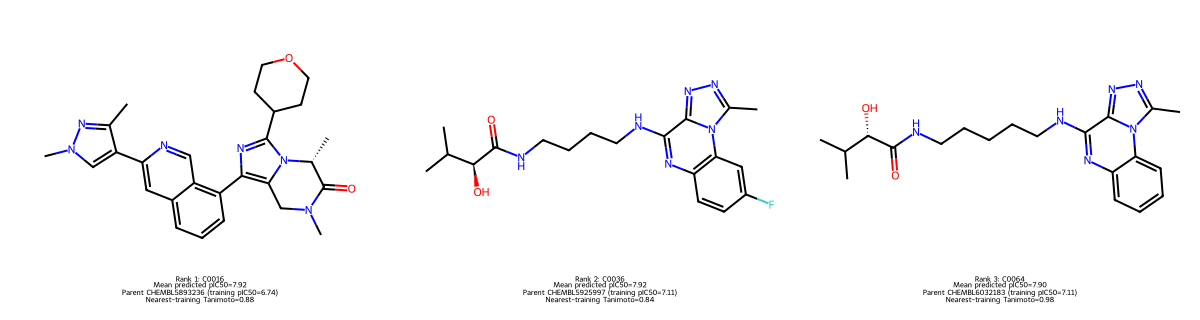

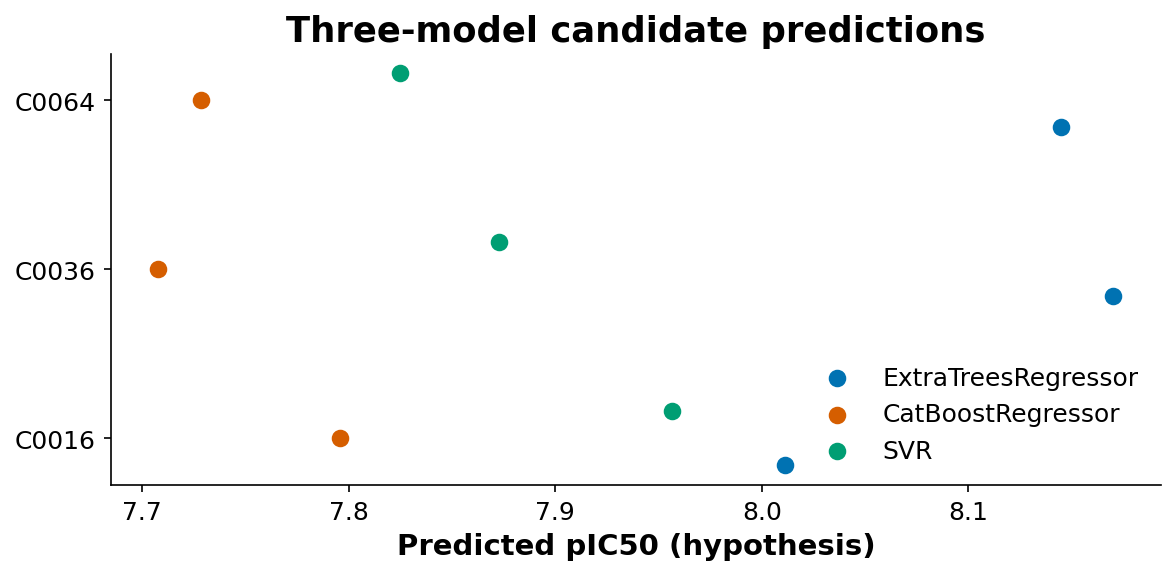

In [11]:
# 7. Select up to three diverse, high-priority candidates and display structures.

import base64
from IPython.display import Image as IPyImage

eligible = scored.loc[
    (scored["nearest_train_tanimoto"] >= 0.65)
    & scored["inside_all_three_ad"]
].copy()

selected_recs = []
selected_fps = []
candidate_ids = candidates["candidate_id"].tolist()

# Greedily select up to three diverse candidates in ranked order.
for row in eligible.itertuples(index=False):
    candidate_position = candidate_ids.index(row.candidate_id)
    fp = candidate_fps[candidate_position]

    too_similar = any(
        DataStructs.TanimotoSimilarity(fp, selected_fp) >= 0.90
        for selected_fp in selected_fps
    )
    if too_similar:
        continue

    selected_recs.append(row.candidate_id)
    selected_fps.append(fp)

    if len(selected_recs) == 3:
        break

recommendations = scored.loc[
    scored["candidate_id"].isin(selected_recs)
].copy()

recommendation_rank = {
    candidate_id: rank
    for rank, candidate_id in enumerate(selected_recs, start=1)
}
recommendations["recommendation_rank"] = (
    recommendations["candidate_id"].map(recommendation_rank)
)
recommendations = recommendations.sort_values(
    "recommendation_rank"
).reset_index(drop=True)

# Add parent and nearest-training structures for review.
extra_columns = candidates.set_index("candidate_id")[
    [
        "parent_is_primary_cliff_member",
        "core",
        "parent_smiles",
        "nearest_train_smiles",
    ]
]
recommendations = recommendations.join(extra_columns, on="candidate_id")

recommendations.to_csv(
    TABLE_DIR / "stage12_top_candidate_recommendations.csv",
    index=False,
)

print(
    f"Eligible candidates: {len(eligible)} | "
    f"distinct recommendations selected: {len(recommendations)}"
)

if recommendations.empty:
    print(
        "No candidates passed every predeclared criterion; "
        "the criteria were not relaxed."
    )

display(recommendations)

# Draw and save the recommended molecular structures.
if not recommendations.empty:
    plot_mols = [
        Chem.MolFromSmiles(smiles)
        for smiles in recommendations["candidate_smiles"]
    ]

    legends = [
        (
            f"Rank {row.recommendation_rank}: {row.candidate_id}\n"
            f"Mean predicted pIC50={row.prediction_mean_pIC50:.2f}\n"
            f"Parent {row.parent_chembl_id} "
            f"(training pIC50={row.parent_pIC50_training:.2f})\n"
            f"Nearest-training Tanimoto={row.nearest_train_tanimoto:.2f}"
        )
        for row in recommendations.itertuples(index=False)
    ]

    grid_result = Draw.MolsToGridImage(
        plot_mols,
        molsPerRow=3,
        subImgSize=(400, 320),
        legends=legends,
        useSVG=False,
        returnPNG=True,
    )

    # RDKit may return bytes or an IPython Image, depending on its version.
    if isinstance(grid_result, (bytes, bytearray, memoryview)):
        png_bytes = bytes(grid_result)
    elif hasattr(grid_result, "data"):
        image_data = grid_result.data
        if isinstance(image_data, str):
            if image_data.startswith("data:image"):
                image_data = image_data.split(",", 1)[1]
            png_bytes = base64.b64decode(image_data)
        else:
            png_bytes = bytes(image_data)
    else:
        raise TypeError(
            "RDKit returned an unsupported image type: "
            f"{type(grid_result).__name__}"
        )

    structure_figure = FIGURE_DIR / "stage12_top_candidate_structures.png"
    structure_figure.write_bytes(png_bytes)
    display(IPyImage(data=png_bytes, format="png"))

# Plot the three model predictions for the recommendations.
if not recommendations.empty:
    fig, ax = plt.subplots(
        figsize=(8, max(4, 0.6 * len(recommendations)))
    )
    y_positions = np.arange(len(recommendations))
    colors = ["#0072B2", "#D55E00", "#009E73"]

    for model_index, model_name in enumerate(MODEL_NAMES):
        ax.scatter(
            recommendations[f"predicted_pIC50_{model_name}"],
            y_positions + (model_index - 1) * 0.16,
            label=model_name,
            color=colors[model_index],
            s=55,
        )

    ax.set_yticks(y_positions, recommendations["candidate_id"])
    ax.set_xlabel("Predicted pIC50 (hypothesis)")
    ax.set_title("Three-model candidate predictions")
    ax.legend(frameon=False)
    fig.tight_layout()

    save_figure(
        fig,
        FIGURE_DIR / "stage12_candidate_prediction_consensus",
    )
    display(fig)
    plt.close(fig)

In [12]:
# 8. Save summary, interpretation notes, and manifest.
summary=pd.DataFrame([{"n_training_molecules":len(train),"n_fixed_features":len(selected),"n_supported_rules_considered":len(ranked_rules),"n_generated_novel_candidates":len(candidates),"n_complete_finite_candidates":len(X_candidate),"n_inside_all_three_AD":int(scored.inside_all_three_ad.sum()),"n_recommendations":len(recommendations),"test_activity_read":False,"models_refit":False,"feature_selection_repeated":False,"recommendation_similarity_min":0.65,"recommendation_inside_all_three_AD":True}])
summary.to_csv(TABLE_DIR/"stage12_summary.csv",index=False);display(summary)
notes=f"""# Stage 12 interpretation notes\n\n- Candidate generation used Stage 11 supported enriching single-cut MMP rules and exact training core/substituent contexts. Low-activity parents and primary activity-cliff members were prioritized for generation.\n- {len(candidates):,} novel analogue structures were generated; the fixed Stage 05 feature set of {len(selected)} columns was reconstructed. Any candidate with a missing or non-finite selected descriptor was excluded without imputation.\n- The saved Stage 08 ExtraTrees, CatBoost, and SVR models were used only for prediction. No model was refitted and no feature selection was repeated.\n- Recommendations require nearest training Morgan Tanimoto >=0.65 and pass all three training-defined AD methods (standardized 5-NN, bounding box, leverage). Greedy diversity avoids selecting candidates with Morgan Tanimoto >=0.90 to an already selected recommendation. If no candidates meet these criteria, no recommendation is made.\n- Predicted pIC50 values and MMP median gains are computational hypotheses, not observed measurements. SHAP values describe fitted model behavior and are not causal evidence. Candidates require synthesis/availability review and experimental testing. No mechanistic or binding-pocket claims are made.\n- Locked-test activities, predictions, and test SHAP files were not used in candidate generation or ranking.\n"""
(STAGE_DIR/"INTERPRETATION_NOTES.md").write_text(notes,encoding="utf-8")
manifest_inputs=[CLEANED,TRAIN_IDS,TRAIN_X,TRAIN_Y,SELECTED,MMP_TRANS,MMP_FRAGS,MMP_PAIRS,CLIFFS]+[OUTPUTS/f"08_final_model_evaluation/models/final_{m}.joblib" for m in MODEL_NAMES]
outputs=sorted(p for p in STAGE_DIR.rglob("*") if p.is_file() and p.name!="manifest.json")
write_manifest("12_candidate_generation_prioritization",{"data_partition":"training/development only","fixed_feature_set":"Stage 05 exact 250 features","models":"saved Stage 08 ExtraTrees, CatBoost, SVR; prediction only","candidate_generation":"supported Stage 11 enriching MMP rules applied in exact training core contexts","recommendation_rule":{"minimum_nearest_training_tanimoto":0.65,"inside_all_AD_methods":True,"maximum_recommendations":3,"pairwise_similarity_below":0.90},"test_activity_read":False,"models_refit":False,"feature_selection_repeated":False},inputs=manifest_inputs,outputs=outputs)
print(f"Stage 12 complete. Tables and figures: {STAGE_DIR}")


,n_training_molecules,n_fixed_features,n_supported_rules_considered,n_generated_novel_candidates,n_complete_finite_candidates,n_inside_all_three_AD,n_recommendations,test_activity_read,models_refit,feature_selection_repeated,recommendation_similarity_min,recommendation_inside_all_three_AD
0,5134,250,25,71,71,61,3,False,False,False,0.65,True


Stage 12 complete. Tables and figures: C:\Users\USER\Documents\E\Code\outputs\12_candidate_generation_prioritization
